# Análise de Acromegalia - SIASUS

Análise de dados de APAC Medicamentos (AM) e Produção Ambulatorial (PA) do SIASUS para acromegalia.


In [1]:
# Função para gerar nome de arquivo com data atual
gerar_nome_arquivo <- function(indicador) {
  data_atual <- format(Sys.Date(), "%Y%m%d")
  return(paste0("../resultados/", data_atual, "_dados2024_", indicador, ".xlsx"))
}

# Função para gerar nome de arquivo PNG
gerar_nome_png <- function(indicador) {
  data_atual <- format(Sys.Date(), "%Y%m%d")
  return(paste0("../resultados/", data_atual, "_dados2024_", indicador, ".png"))
}

cat("Funções de formatação de data criadas!\n")
cat("Data atual:", format(Sys.Date(), "%Y%m%d"), "\n")



Funções de formatação de data criadas!
Data atual: 20260720 


## 1. Importação de Dados


In [2]:
# Carregar pacotes necessários
library(tidyverse)
library(lubridate)
library(readr)
library(stringr)
library(purrr)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
# Carregar funções personalizadas
source("func/functions.R")


In [4]:
# Definir caminhos dos dados
caminho_dados <- "../data/raw"
caminho_saida <- "../data/processed"

# Criar diretório de saída se não existir
if (!dir.exists(caminho_saida)) {
  dir.create(caminho_saida, recursive = TRUE)
}

### Carregamento dos Dados


In [5]:
# Carregar dados de medicamentos (AM)
data_am <- list.files("../data/processed/medicamentos/", pattern = "\\.csv$", full.names = TRUE) %>%
  map_dfr(~ read_csv(.x, col_types = cols(.default = col_character())))

cat("Dados AM carregados:", nrow(data_am), "registros\n")
cat("Autorizações únicas AM:", n_distinct(data_am$AP_AUTORIZ), "\n")
cat("Autorizações AM com AP_AUTORIZ nulo:", sum(is.na(data_am$AP_AUTORIZ)), "\n")
cat("Pacientes únicos AM:", n_distinct(data_am$AP_CNSPCN), "\n")

Dados AM carregados: 84042 registros
Autorizações únicas AM: 39254 
Autorizações AM com AP_AUTORIZ nulo: 0 
Pacientes únicos AM: 4989 


In [6]:
# Carregar dados de produção ambulatorial (PA)
data_pa <- list.files("../data/processed/producao_ambulatorial/", pattern = "\\.csv$", full.names = TRUE) %>%
  map_dfr(~ read_csv(.x, col_types = cols(.default = col_character())))

cat("Dados PA carregados:", nrow(data_pa), "registros\n")
cat("Autorizações únicas PA:", n_distinct(data_pa$PA_AUTORIZ), "\n")
cat("Autorizações PA com PA_AUTORIZ nulo:", sum(is.na(data_pa$PA_AUTORIZ)), "\n")

Dados PA carregados: 97280 registros
Autorizações únicas PA: 30896 
Autorizações PA com PA_AUTORIZ nulo: 0 


## 2. Preparação dos Dados


In [7]:
# Transformar dados para padronização

## Dados de id da autorização (apenas se não for nulo)
data_am$AP_AUTORIZ <- ifelse(is.na(data_am$AP_AUTORIZ), NA, str_pad(as.character(data_am$AP_AUTORIZ), width = 15, pad = "0"))
data_pa$PA_AUTORIZ <- ifelse(is.na(data_pa$PA_AUTORIZ), NA, str_pad(as.character(data_pa$PA_AUTORIZ), width = 15, pad = "0"))

## Dados da unidade de saúde
data_am$AP_CODUNI <- str_pad(as.character(data_am$AP_CODUNI), width = 7, pad = "0")
data_pa$PA_CODUNI <- str_pad(as.character(data_pa$PA_CODUNI), width = 7, pad = "0")

## Dados do município
data_am$AP_MUNPCN <- str_pad(as.character(data_am$AP_MUNPCN), width = 7, pad = "0")
data_pa$PA_UFMUN <- str_pad(as.character(data_pa$PA_UFMUN), width = 7, pad = "0")

## Dados de data de competência (formato YYYY-MM-DD)
data_am$AP_CMP <- as.Date(paste0(data_am$AP_CMP, "01"), format = "%Y%m%d")
data_pa$PA_CMP <- as.Date(paste0(data_pa$PA_CMP, "01"), format = "%Y%m%d")

## Dados de data de movimentação (formato YYYY-MM-DD)
data_am$AP_MVM <- as.Date(paste0(data_am$AP_MVM, "01"), format = "%Y%m%d")
data_pa$PA_MVM <- as.Date(paste0(data_pa$PA_MVM, "01"), format = "%Y%m%d")

cat("Dados transformados com sucesso!\n")
cat("Formato de datas: YYYY-MM-DD\n")

Dados transformados com sucesso!
Formato de datas: YYYY-MM-DD


## 3. União dos Dados (AM + PA)


In [8]:
# Realizar o join entre AM e PA
dados_unificados <- data_am %>%
  left_join(data_pa, by = c(
    "AP_AUTORIZ" = "PA_AUTORIZ",
    "AP_CMP" = "PA_CMP",
    "AP_MVM" = "PA_MVM"
  ))

cat("Dados unificados:", nrow(dados_unificados), "registros\n")
cat("Autorizações únicas unificadas:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("Pacientes únicos unificados:", n_distinct(dados_unificados$AP_CNSPCN), "\n")

Dados unificados: 103204 registros
Autorizações únicas unificadas: 39254 
Pacientes únicos unificados: 4989 


## 4. Filtro para o Ano de 2024


In [9]:
# Filtrar dados para o ano de 2024
dados_unificados <- dados_unificados %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31"))

cat("Dados filtrados para 2024:", nrow(dados_unificados), "registros\n")
cat("Autorizações únicas em 2024:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("Pacientes únicos em 2024:", n_distinct(dados_unificados$AP_CNSPCN), "\n")
cat("✅ Dataset unificado agora contém APENAS dados de 2024\n")

Dados filtrados para 2024: 47743 registros
Autorizações únicas em 2024: 19053 
Pacientes únicos em 2024: 4232 
✅ Dataset unificado agora contém APENAS dados de 2024


## 5. Resumo dos Dados Finais


In [10]:
# Resumo final dos dados
cat("=== RESUMO FINAL DOS DADOS UNIFICADOS ===\n\n")
cat("📊 DADOS UNIFICADOS (AM + PA) - 2024:\n")
cat("  • Total de registros:", nrow(dados_unificados), "\n")
cat("  • Total de autorizações únicas:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("  • Total de pacientes únicos:", n_distinct(dados_unificados$AP_CNSPCN), "\n\n")

# Calcular autorizações sem paciente vinculado
autorizacoes_sem_paciente <- dados_unificados %>%
  filter(is.na(AP_CNSPCN)) %>%
  summarise(total = n_distinct(AP_AUTORIZ)) %>%
  pull(total)

cat("🔍 ANÁLISE DE COMPLETUDE:\n")
cat("  • Autorizações sem paciente vinculado:", autorizacoes_sem_paciente, "\n")
cat("  • Percentual de autorizações sem paciente:", round(autorizacoes_sem_paciente / n_distinct(dados_unificados$AP_AUTORIZ) * 100, 2), "%\n\n")

cat("📅 PERÍODO DOS DADOS:\n")
cat("  • Data mínima:", as.character(min(dados_unificados$AP_CMP, na.rm = TRUE)), "\n")
cat("  • Data máxima:", as.character(max(dados_unificados$AP_CMP, na.rm = TRUE)), "\n\n")

cat("✅ DADOS PRONTOS PARA ANÁLISE!\n")

=== RESUMO FINAL DOS DADOS UNIFICADOS ===

📊 DADOS UNIFICADOS (AM + PA) - 2024:
  • Total de registros: 47743 
  • Total de autorizações únicas: 19053 
  • Total de pacientes únicos: 4232 



🔍 ANÁLISE DE COMPLETUDE:
  • Autorizações sem paciente vinculado: 282 
  • Percentual de autorizações sem paciente: 1.48 %

📅 PERÍODO DOS DADOS:
  • Data mínima: 2024-01-01 
  • Data máxima: 2024-12-01 

✅ DADOS PRONTOS PARA ANÁLISE!


## 6. Análise Demográfica por Pacientes Únicos


In [11]:
# Preparar dados para análise demográfica
# Garantir que estamos trabalhando apenas com dados de 2024
dados_2024 <- dados_unificados %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31"))

# Selecionar APENAS UMA autorização por paciente (AP_CNSPCN) em 2024
# Se houver empate na data, pegar apenas a primeira ocorrência
dados_pacientes_unicos <- dados_2024 %>%
  group_by(AP_CNSPCN) %>%
  arrange(desc(AP_CMP), desc(AP_AUTORIZ)) %>%  # Ordenar por data desc e autorização desc
  slice(1) %>%  # Pegar apenas a primeira linha (mais recente)
  ungroup()

cat("Dados de pacientes únicos de 2024 preparados:\n")
cat("  • Total de registros em 2024:", nrow(dados_2024), "\n")
cat("  • Total de pacientes únicos (AP_CNSPCN únicos):", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("  • Total de linhas em dados_pacientes_unicos:", nrow(dados_pacientes_unicos), "\n")
cat("  • Período das autorizações mais recentes:", 
    as.character(min(dados_pacientes_unicos$AP_CMP, na.rm = TRUE)), 
    "a", 
    as.character(max(dados_pacientes_unicos$AP_CMP, na.rm = TRUE)), "\n")

# Validação crítica: garantir que temos exatamente 4232 linhas
if(nrow(dados_pacientes_unicos) == 4232) {
  cat("✅ SUCESSO: dados_pacientes_unicos tem exatamente 4232 linhas!\n")
} else {
  cat("❌ ERRO: dados_pacientes_unicos tem", nrow(dados_pacientes_unicos), "linhas, deveria ter 4232!\n")
}

Dados de pacientes únicos de 2024 preparados:
  • Total de registros em 2024: 47743 
  • Total de pacientes únicos (AP_CNSPCN únicos): 4232 
  • Total de linhas em dados_pacientes_unicos: 4232 
  • Período das autorizações mais recentes: 2024-01-01 a 2024-12-01 
✅ SUCESSO: dados_pacientes_unicos tem exatamente 4232 linhas!


### 6.1 Análise por Sexo


In [12]:
# Calcular quantidade de pacientes únicos por sexo
# IMPORTANTE: Contar apenas AP_CNSPCN únicos, não registros
pacientes_por_sexo <- dados_pacientes_unicos %>%
  group_by(AP_SEXO) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos por sexo
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_sexo <- pacientes_por_sexo %>%
  summarise(
    AP_SEXO = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_sexo_com_total <- bind_rows(pacientes_por_sexo, total_sexo)

cat("Distribuição de pacientes únicos por sexo:\n")
print(pacientes_por_sexo_com_total)

# Validação: verificar se o total está correto
total_sexo_validacao <- sum(pacientes_por_sexo$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por sexo:", total_sexo_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("✅ Total correto de pacientes únicos em 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

Distribuição de pacientes únicos por sexo:
# A tibble: 3 × 3
  AP_SEXO quantidade_pacientes percentual
  <chr>                  <int>      <dbl>
1 F                       2601       61.5
2 M                       1631       38.5
3 TOTAL                   4232      100  

✅ Validação - Total de pacientes únicos por sexo: 4232 
✅ Deve ser igual a: 4232 
✅ Total correto de pacientes únicos em 2024: 4232 


In [13]:
# Exportar tabela de sexo para Excel
library(openxlsx)

# Criar diretório de resultados se não existir
if (!dir.exists("../resultados")) {
  dir.create("../resultados", recursive = TRUE)
}

# Exportar para Excel
write.xlsx(pacientes_por_sexo_com_total, 
           gerar_nome_arquivo("sexo"),
           sheetName = "Pacientes por Sexo",
           rowNames = FALSE)

cat("✅ Tabela de pacientes por sexo exportada para:", gerar_nome_arquivo("sexo"), "
")



✅ Tabela de pacientes por sexo exportada para: ../resultados/20260720_dados2024_sexo.xlsx 


### 6.2 Análise por Idade


In [14]:
# Calcular quantidade de pacientes únicos por idade
# IMPORTANTE: Contar apenas AP_CNSPCN únicos, não registros
# Primeiro, converter PA_IDADE para numérico
dados_pacientes_unicos$PA_IDADE <- as.numeric(dados_pacientes_unicos$PA_IDADE)

# Criar faixas etárias
pacientes_por_idade <- dados_pacientes_unicos %>%
  mutate(
    faixa_etaria = case_when(
      is.na(PA_IDADE) ~ "Idade desconhecida",
      PA_IDADE < 18 ~ "< 18 anos",
      PA_IDADE >= 18 & PA_IDADE <= 29 ~ "18 a 29 anos",
      PA_IDADE >= 30 & PA_IDADE <= 39 ~ "30 a 39 anos",
      PA_IDADE >= 40 & PA_IDADE <= 49 ~ "40 a 49 anos",
      PA_IDADE >= 50 & PA_IDADE <= 59 ~ "50 a 59 anos",
      PA_IDADE >= 60 & PA_IDADE <= 69 ~ "60 a 69 anos",
      PA_IDADE >= 70 & PA_IDADE <= 79 ~ "70 a 79 anos",
      PA_IDADE >= 80 ~ "80 anos ou mais",
      TRUE ~ "Idade inválida"
    )
  ) %>%
  mutate(faixa_etaria = factor(faixa_etaria, levels = c(
    "< 18 anos",
    "18 a 29 anos", 
    "30 a 39 anos",
    "40 a 49 anos",
    "50 a 59 anos",
    "60 a 69 anos",
    "70 a 79 anos",
    "80 anos ou mais",
    "Idade desconhecida",
    "Idade inválida"
  ))) %>%
  group_by(faixa_etaria) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos por faixa etária
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(faixa_etaria)

# Adicionar linha de total
total_idade <- pacientes_por_idade %>%
  summarise(
    faixa_etaria = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_idade_com_total <- bind_rows(pacientes_por_idade, total_idade)

cat("Distribuição de pacientes únicos por faixa etária:\n")
print(pacientes_por_idade_com_total)

# Validação: verificar se o total está correto
total_idade_validacao <- sum(pacientes_por_idade$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por idade:", total_idade_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("✅ Total correto de pacientes únicos em 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

Distribuição de pacientes únicos por faixa etária:
# A tibble: 10 × 3
   faixa_etaria       quantidade_pacientes percentual
   <chr>                             <int>      <dbl>
 1 < 18 anos                            22       0.52
 2 18 a 29 anos                        160       3.78
 3 30 a 39 anos                        458      10.8 
 4 40 a 49 anos                        842      19.9 
 5 50 a 59 anos                        905      21.4 
 6 60 a 69 anos                        822      19.4 
 7 70 a 79 anos                        416       9.83
 8 80 anos ou mais                     139       3.28
 9 Idade desconhecida                  468      11.1 
10 TOTAL                              4232     100   

✅ Validação - Total de pacientes únicos por idade: 4232 
✅ Deve ser igual a: 4232 
✅ Total correto de pacientes únicos em 2024: 4232 


In [15]:
# Exportar tabela de idade para Excel
write.xlsx(pacientes_por_idade_com_total, 
           gerar_nome_arquivo("idade"),
           sheetName = "Pacientes por Idade",
           rowNames = FALSE)

cat("✅ Tabela de pacientes por idade exportada para:", gerar_nome_arquivo("idade"), "\n")

✅ Tabela de pacientes por idade exportada para: ../resultados/20260720_dados2024_idade.xlsx 


### 6.3 Pirâmide Etária


In [16]:
# Preparar dados para pirâmide etária
# Criar faixas etárias e contar pacientes únicos por sexo e idade
dados_piramide <- dados_pacientes_unicos %>%
  mutate(
    faixa_etaria = case_when(
      is.na(PA_IDADE) ~ "Idade desconhecida",
      PA_IDADE < 18 ~ "< 18 anos",
      PA_IDADE >= 18 & PA_IDADE <= 29 ~ "18-29 anos",
      PA_IDADE >= 30 & PA_IDADE <= 39 ~ "30-39 anos",
      PA_IDADE >= 40 & PA_IDADE <= 49 ~ "40-49 anos",
      PA_IDADE >= 50 & PA_IDADE <= 59 ~ "50-59 anos",
      PA_IDADE >= 60 & PA_IDADE <= 69 ~ "60-69 anos",
      PA_IDADE >= 70 & PA_IDADE <= 79 ~ "70-79 anos",
      PA_IDADE >= 80 ~ "80+ anos",
      TRUE ~ "Idade inválida"
    ),
    sexo_tratado = case_when(
      AP_SEXO %in% c("F", "M") ~ AP_SEXO,
      is.na(AP_SEXO) | AP_SEXO == "" ~ "Sexo desconhecido",
      TRUE ~ "Sexo inválido"
    )
  ) %>%
  mutate(
    faixa_etaria = factor(faixa_etaria, levels = c(
      "< 18 anos",
      "18-29 anos", 
      "30-39 anos",
      "40-49 anos",
      "50-59 anos",
      "60-69 anos",
      "70-79 anos",
      "80+ anos",
      "Idade desconhecida"
    )),
    sexo_tratado = factor(sexo_tratado, levels = c("F", "M", "Sexo desconhecido", "Sexo inválido"))
  ) %>%
  group_by(faixa_etaria, sexo_tratado) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  # Para pirâmide, usar valores negativos para homens
  mutate(
    qtd_plot = case_when(
      sexo_tratado == "M" ~ -quantidade_pacientes,
      sexo_tratado == "F" ~ quantidade_pacientes,
      TRUE ~ 0  # outros sexos não aparecem na pirâmide
    )
  )


✅ Pirâmide etária salva em: ../resultados/20260720_dados2024_piramide_etaria.png 


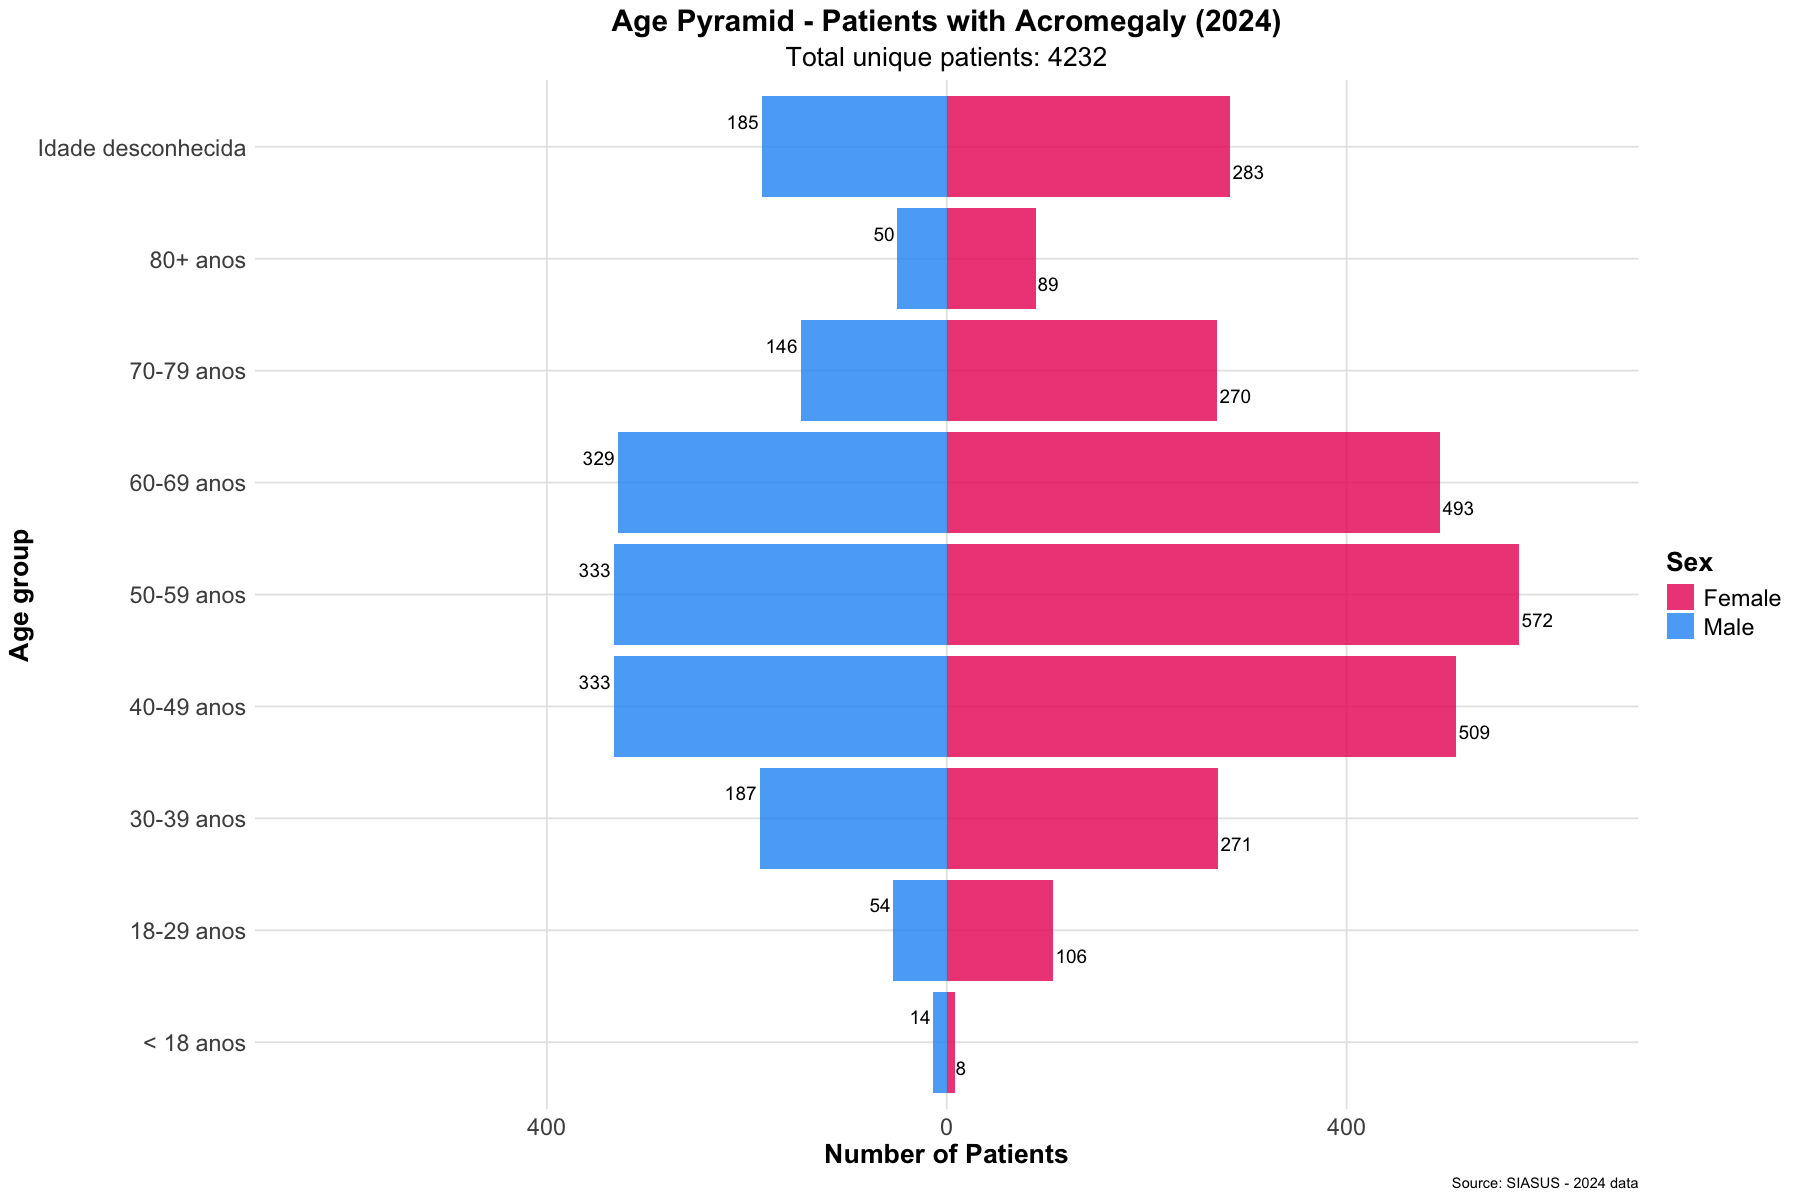

In [17]:
# Criar pirâmide etária
library(ggplot2)

# Filtrar apenas F e M para a pirâmide
dados_piramide_plot <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M"))

# Calcular máximo para ajustar escala
max_valor <- max(abs(dados_piramide_plot$qtd_plot))

# Criar pirâmide etária
piramide_etaria <- ggplot(dados_piramide_plot, aes(x = faixa_etaria, y = qtd_plot, fill = sexo_tratado)) +
  geom_bar(stat = "identity", position = "identity", alpha = 0.8) +
  coord_flip() +
  scale_y_continuous(
    labels = function(x) abs(x),
    limits = c(-max_valor * 1.1, max_valor * 1.1)
  ) +
  scale_fill_manual(
    values = c("F" = "#E91E63", "M" = "#2196F3"),
    labels = c("F" = "Female", "M" = "Male")
  ) +
  labs(
    title = "Age Pyramid - Patients with Acromegaly (2024)",
    subtitle = paste("Total unique patients:", n_distinct(dados_pacientes_unicos$AP_CNSPCN)),
    x = "Age group",
    y = "Number of Patients",
    fill = "Sex",
    caption = "Source: SIASUS - 2024 data"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    plot.subtitle = element_text(size = 16, hjust = 0.5),
    axis.text.x = element_text(size = 14),
    axis.text.y = element_text(size = 14),
    axis.title = element_text(size = 16, face = "bold"),
    legend.title = element_text(size = 16, face = "bold"),
    legend.text = element_text(size = 14),
    panel.grid.major = element_line(color = "grey90"),
    panel.grid.minor = element_blank()
  ) +
  geom_text(
    aes(label = ifelse(qtd_plot != 0, abs(qtd_plot), "")),
    position = position_dodge(width = 0.9),
    hjust = ifelse(dados_piramide_plot$qtd_plot >= 0, -0.1, 1.1),
    size = 4,
    color = "black"
  )

# Configurar tamanho da exibição no notebook
options(repr.plot.width = 15, repr.plot.height = 10)

# Exibir gráfico com tamanho maior
print(piramide_etaria)

# Salvar gráfico
ggsave(gerar_nome_png("piramide_etaria"), 
       plot = piramide_etaria, 
       width = 15, height = 10, dpi = 300)

cat("\n✅ Pirâmide etária salva em:", gerar_nome_png("piramide_etaria"), "\n")

In [18]:
# Resumo estatístico da pirâmide etária
cat("=== RESUMO DA PIRÂMIDE ETÁRIA ===\n\n")

# Estatísticas por sexo
resumo_sexo <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M")) %>%
  group_by(sexo_tratado) %>%
  summarise(
    total_pacientes = sum(quantidade_pacientes),
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(total_pacientes / sum(total_pacientes) * 100, 1)
  )

# Adicionar linha de total
total_resumo_sexo <- resumo_sexo %>%
  summarise(
    sexo_tratado = "TOTAL",
    total_pacientes = sum(total_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
resumo_sexo_com_total <- bind_rows(resumo_sexo, total_resumo_sexo)

cat("Distribuição por sexo:\n")
print(resumo_sexo_com_total)

# Estatísticas por faixa etária
resumo_idade <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M")) %>%
  group_by(faixa_etaria) %>%
  summarise(
    total_pacientes = sum(quantidade_pacientes),
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(total_pacientes / sum(total_pacientes) * 100, 1)
  ) %>%
  arrange(faixa_etaria)

# Adicionar linha de total
total_resumo_idade <- resumo_idade %>%
  summarise(
    faixa_etaria = "TOTAL",
    total_pacientes = sum(total_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
resumo_idade_com_total <- bind_rows(resumo_idade, total_resumo_idade)

cat("\nDistribuição por faixa etária:\n")
print(resumo_idade_com_total)

# Idade mediana por sexo
idade_mediana <- dados_pacientes_unicos %>%
  filter(AP_SEXO %in% c("F", "M")) %>%
  group_by(AP_SEXO) %>%
  summarise(
    idade_mediana = median(as.numeric(PA_IDADE), na.rm = TRUE),
    idade_media = round(mean(as.numeric(PA_IDADE), na.rm = TRUE), 1),
    .groups = "drop"
  )

cat("\nIdade mediana e média por sexo:\n")
print(idade_mediana)

=== RESUMO DA PIRÂMIDE ETÁRIA ===

Distribuição por sexo:
# A tibble: 3 × 3
  sexo_tratado total_pacientes percentual
  <chr>                  <int>      <dbl>
1 F                       2601       61.5
2 M                       1631       38.5
3 TOTAL                   4232      100  

Distribuição por faixa etária:
# A tibble: 10 × 3
   faixa_etaria       total_pacientes percentual
   <chr>                        <int>      <dbl>
 1 < 18 anos                       22        0.5
 2 18-29 anos                     160        3.8
 3 30-39 anos                     458       10.8
 4 40-49 anos                     842       19.9
 5 50-59 anos                     905       21.4
 6 60-69 anos                     822       19.4
 7 70-79 anos                     416        9.8
 8 80+ anos                       139        3.3
 9 Idade desconhecida             468       11.1
10 TOTAL                         4232      100  

Idade mediana e média por sexo:
# A tibble: 2 × 3
  AP_SEXO idade_mediana 

### 6.4 Análise por Raça/Cor


In [19]:
# Análise por raça/cor
# Primeiro, vamos verificar quais valores existem na coluna PA_RACACOR
cat("Valores únicos em PA_RACACOR:\n")
print(unique(dados_pacientes_unicos$PA_RACACOR))

# Criar tabela de raça/cor com nomes padronizados
pacientes_por_raca_cor <- dados_pacientes_unicos %>%
  mutate(
    raca_cor = case_when(
      PA_RACACOR == "01" ~ "Branca",
      PA_RACACOR == "02" ~ "Preta",
      PA_RACACOR == "03" ~ "Amarela",
      PA_RACACOR == "04" ~ "Parda",
      PA_RACACOR == "05" ~ "Indígena",
      PA_RACACOR == "99" ~ "Não informado",
      is.na(PA_RACACOR) | PA_RACACOR == "" ~ "Não informado",
      TRUE ~ "Outros"
    )
  ) %>%
  group_by(raca_cor) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_raca_cor <- pacientes_por_raca_cor %>%
  summarise(
    raca_cor = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_raca_cor_com_total <- bind_rows(pacientes_por_raca_cor, total_raca_cor)

cat("Distribuição de pacientes únicos por raça/cor:\n")
print(pacientes_por_raca_cor_com_total)

# Validação
total_raca_cor_validacao <- sum(pacientes_por_raca_cor$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por raça/cor:", total_raca_cor_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
library(openxlsx)
write.xlsx(pacientes_por_raca_cor_com_total, gerar_nome_arquivo("raca_cor"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("raca_cor"), "\n")

Valores únicos em PA_RACACOR:
[1] NA   "01" "03" "04" "02"
Distribuição de pacientes únicos por raça/cor:
# A tibble: 6 × 3
  raca_cor      quantidade_pacientes percentual
  <chr>                        <int>      <dbl>
1 Branca                        2142      50.6 
2 Amarela                       1363      32.2 
3 Não informado                  468      11.1 
4 Preta                          183       4.32
5 Parda                           76       1.8 
6 TOTAL                         4232     100   

✅ Validação - Total de pacientes únicos por raça/cor: 4232 
✅ Deve ser igual a: 4232 
✅ Tabela exportada para: ../resultados/20260720_dados2024_raca_cor.xlsx 


### 6.5 Análise por UF (Unidade Federativa)


In [20]:
# Análise por UF
# Extrair UF dos 3 primeiros dígitos de AP_UFMUN
# Primeiro, vamos verificar alguns valores de AP_UFMUN
cat("Primeiros valores de AP_UFMUN:\n")
print(head(dados_pacientes_unicos$AP_UFMUN, 10))

# Verificar códigos UF únicos encontrados
codigos_uf_encontrados <- dados_pacientes_unicos %>%
  mutate(codigo_uf = substr(AP_UFMUN, 1, 2)) %>%
  count(codigo_uf, sort = TRUE)

cat("\nCódigos UF encontrados nos dados:\n")
print(codigos_uf_encontrados)

# Criar mapeamento de código UF para sigla
codigo_uf_para_sigla <- data.frame(
  codigo_uf = c("11", "12", "13", "14", "15", "16", "17", "21", "22", "23", 
                "24", "25", "26", "27", "28", "29", "31", "32", "33", "35", 
                "41", "42", "43", "50", "51", "52", "53"),
  uf_sigla = c("RO", "AC", "AM", "RR", "PA", "AP", "TO", "MA", "PI", "CE", 
               "RN", "PB", "PE", "AL", "SE", "BA", "MG", "ES", "RJ", "SP", 
               "PR", "SC", "RS", "MS", "MT", "GO", "DF")
)

# Criar tabela de UF
pacientes_por_uf <- dados_pacientes_unicos %>%
  mutate(
    codigo_uf = substr(AP_UFMUN, 1, 2)  # Extrair 2 primeiros dígitos (código da UF)
  ) %>%
  left_join(codigo_uf_para_sigla, by = "codigo_uf") %>%
  mutate(
    uf_sigla = ifelse(is.na(uf_sigla), "Não identificado", uf_sigla)
  ) %>%
  group_by(uf_sigla) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_uf <- pacientes_por_uf %>%
  summarise(
    uf_sigla = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_uf_com_total <- bind_rows(pacientes_por_uf, total_uf)

cat("Distribuição de pacientes únicos por UF:\n")
print(pacientes_por_uf_com_total)

# Validação
total_uf_validacao <- sum(pacientes_por_uf$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por UF:", total_uf_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
write.xlsx(pacientes_por_uf_com_total, gerar_nome_arquivo("uf"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("uf"), "\n")

Primeiros valores de AP_UFMUN:
 [1] "310160" "420540" "431490" "500270" "355030" "352900" "355030" "350320"
 [9] "292740" "355030"

Códigos UF encontrados nos dados:
# A tibble: 27 × 2
   codigo_uf     n
   <chr>     <int>
 1 35         1567
 2 31          462
 3 43          302
 4 41          252
 5 33          205
 6 23          188
 7 42          178
 8 29          135
 9 21          108
10 26          108
# ℹ 17 more rows
Distribuição de pacientes únicos por UF:
# A tibble: 28 × 3
   uf_sigla quantidade_pacientes percentual
   <chr>                   <int>      <dbl>
 1 SP                       1567      37.0 
 2 MG                        462      10.9 
 3 RS                        302       7.14
 4 PR                        252       5.95
 5 RJ                        205       4.84
 6 CE                        188       4.44
 7 SC                        178       4.21
 8 BA                        135       3.19
 9 MA                        108       2.55
10 PE                     

### 6.6 Análise por Região


In [21]:
# Análise por Região
# Criar mapeamento de UF para Região usando as siglas
uf_para_regiao <- data.frame(
  uf_sigla = c("AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO", "MA", 
               "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI", "RJ", "RN", 
               "RS", "RO", "RR", "SC", "SP", "SE", "TO"),
  regiao = c("Norte", "Nordeste", "Norte", "Norte", "Nordeste", "Nordeste", 
             "Centro-Oeste", "Sudeste", "Centro-Oeste", "Nordeste",
             "Centro-Oeste", "Centro-Oeste", "Sudeste", "Norte", "Nordeste", 
             "Sul", "Nordeste", "Nordeste", "Sudeste", "Nordeste",
             "Sul", "Norte", "Norte", "Sul", "Sudeste", "Nordeste", "Norte")
)

# Criar tabela de região usando os dados já processados de UF
pacientes_por_regiao <- dados_pacientes_unicos %>%
  mutate(
    codigo_uf = substr(AP_UFMUN, 1, 2)  # Extrair 2 primeiros dígitos (código da UF)
  ) %>%
  left_join(codigo_uf_para_sigla, by = "codigo_uf") %>%
  mutate(
    uf_sigla = ifelse(is.na(uf_sigla), "Não identificado", uf_sigla)
  ) %>%
  left_join(uf_para_regiao, by = "uf_sigla") %>%
  mutate(
    regiao = ifelse(is.na(regiao), "Não informado", regiao)
  ) %>%
  group_by(regiao) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_regiao <- pacientes_por_regiao %>%
  summarise(
    regiao = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_regiao_com_total <- bind_rows(pacientes_por_regiao, total_regiao)

cat("Distribuição de pacientes únicos por região:\n")
print(pacientes_por_regiao_com_total)

# Validação
total_regiao_validacao <- sum(pacientes_por_regiao$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por região:", total_regiao_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
write.xlsx(pacientes_por_regiao_com_total, gerar_nome_arquivo("regiao"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("regiao"), "\n")

Distribuição de pacientes únicos por região:


# A tibble: 6 × 3
  regiao       quantidade_pacientes percentual
  <chr>                       <int>      <dbl>
1 Sudeste                      2320      54.8 
2 Nordeste                      784      18.5 
3 Sul                           732      17.3 
4 Centro-Oeste                  270       6.38
5 Norte                         126       2.98
6 TOTAL                        4232     100   

✅ Validação - Total de pacientes únicos por região: 4232 
✅ Deve ser igual a: 4232 
✅ Tabela exportada para: ../resultados/20260720_dados2024_regiao.xlsx 


In [22]:
# Resumo geral das análises demográficas
cat("=== RESUMO GERAL DAS ANÁLISES DEMOGRÁFICAS ===\n\n")

cat("📊 TOTAL DE PACIENTES ÚNICOS EM 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n\n")

cat("📋 TABELAS GERADAS:\n")
cat("  • Pacientes por sexo:", gerar_nome_arquivo("sexo"), "
")
cat("  • Pacientes por idade:", gerar_nome_arquivo("idade"), "
")
cat("  • Pacientes por raça/cor: ../resultados/pacientes_unicos_por_raca_cor_2024.xlsx\n")
cat("  • Pacientes por UF: ../resultados/pacientes_unicos_por_uf_2024.xlsx\n")
cat("  • Pacientes por região: ../resultados/pacientes_unicos_por_regiao_2024.xlsx\n")
cat("  • Pirâmide etária: ../resultados/piramide_etaria_2024.png\n\n")

cat("✅ Todas as análises demográficas foram concluídas com sucesso!\n")
cat("✅ Todas as contagens são baseadas em AP_CNSPCN únicos (4232 pacientes)\n")
cat("✅ Todas as tabelas incluem linha de total e percentuais\n")
cat("✅ Validações confirmam consistência dos dados\n")

=== RESUMO GERAL DAS ANÁLISES DEMOGRÁFICAS ===

📊 TOTAL DE PACIENTES ÚNICOS EM 2024: 4232 

📋 TABELAS GERADAS:
  • Pacientes por sexo: ../resultados/20260720_dados2024_sexo.xlsx 


  • Pacientes por idade: ../resultados/20260720_dados2024_idade.xlsx 
  • Pacientes por raça/cor: ../resultados/pacientes_unicos_por_raca_cor_2024.xlsx
  • Pacientes por UF: ../resultados/pacientes_unicos_por_uf_2024.xlsx
  • Pacientes por região: ../resultados/pacientes_unicos_por_regiao_2024.xlsx
  • Pirâmide etária: ../resultados/piramide_etaria_2024.png

✅ Todas as análises demográficas foram concluídas com sucesso!
✅ Todas as contagens são baseadas em AP_CNSPCN únicos (4232 pacientes)
✅ Todas as tabelas incluem linha de total e percentuais
✅ Validações confirmam consistência dos dados


## 7. Análise de Medicamentos


### 7.1 Dicionário de Medicamentos SIGTAP


In [23]:
# Dicionário de medicamentos SIGTAP (AP_PRIPAL) - Acromegalia
# Incluindo prefixo "06" que aparece nos dados
codigo_nomes <- c(
    "0604290039" = "OCTREOTIDA LAR 30 MG INJETÁVEL",
    "0604290080" = "LANREOTIDA 120 MG INJETÁVEL",
    "0604030037" = "CABERGOLINA 0,5 MG",
    "0604290020" = "OCTREOTIDA LAR 20 MG INJETÁVEL",
    "0604290071" = "LANREOTIDA 90 MG INJETÁVEL",
    "0604290063" = "LANREOTIDA 60 MG INJETÁVEL",
    "0604290012" = "OCTREOTIDA LAR 10 MG INJETÁVEL",
    "0604290047" = "OCTREOTIDA 0,1 MG/ML INJETÁVEL"
)

### 7.2 Combinações de Medicamentos por Paciente


In [24]:
# Verificar códigos únicos em AP_PRIPAL
cat("Códigos únicos encontrados em AP_PRIPAL:\n")
codigos_unicos <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  count(AP_PRIPAL, sort = TRUE)
print(codigos_unicos)

# Verificar se os códigos do dicionário estão presentes nos dados
cat("\nCódigos do dicionário presentes nos dados:\n")
codigos_dicionario <- names(codigo_nomes)
codigos_presentes <- codigos_unicos %>%
  filter(AP_PRIPAL %in% codigos_dicionario)
print(codigos_presentes)

# Testar o mapeamento diretamente
cat("\nTeste de mapeamento:\n")
teste_mapeamento <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  select(AP_PRIPAL) %>%
  distinct() %>%
  head(5) %>%
  mutate(
    AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)
  )
print(teste_mapeamento)

# Verificar se os códigos nos dados têm prefixo "06"
cat("\nVerificando se códigos têm prefixo '06':\n")
codigos_com_prefixo <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  mutate(
    codigo_sem_prefixo = ifelse(str_starts(AP_PRIPAL, "06"), substr(AP_PRIPAL, 3, nchar(AP_PRIPAL)), AP_PRIPAL)
  ) %>%
  select(AP_PRIPAL, codigo_sem_prefixo) %>%
  distinct() %>%
  head(10)
print(codigos_com_prefixo)

# Criar tabela de combinações de medicamentos por paciente
# APLICAR O DICIONÁRIO PRIMEIRO, DEPOIS AGRUPAR PELOS NOMES
combinacoes_medicamentos <- dados_unificados %>%
  filter(!is.na(AP_CNSPCN) & !is.na(AP_PRIPAL)) %>%
  mutate(AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_CNSPCN) %>%
  summarise(
    medicamentos = paste(sort(unique(AP_PRIPAL_NOME)), collapse = " + "),
    quantidade_medicamentos = n_distinct(AP_PRIPAL_NOME),
    .groups = "drop"
  ) %>%
  group_by(medicamentos) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_combinacoes <- combinacoes_medicamentos %>%
  summarise(
    medicamentos = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes)
  )

# Combinar dados com total
combinacoes_medicamentos_com_total <- bind_rows(combinacoes_medicamentos, total_combinacoes)

cat("Combinações de medicamentos por paciente:\n")
print(combinacoes_medicamentos_com_total)

# Validação
total_combinacoes_validacao <- sum(combinacoes_medicamentos$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes com combinações:", total_combinacoes_validacao, "\n")

# Exportar para Excel
write.xlsx(combinacoes_medicamentos_com_total, gerar_nome_arquivo("combinacoes_medicamentos"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("combinacoes_medicamentos"), "\n")

Códigos únicos encontrados em AP_PRIPAL:
# A tibble: 8 × 2
  AP_PRIPAL      n
  <chr>      <int>
1 0604030037 21174
2 0604290039  8352
3 0604290020  7305
4 0604290080  7248
5 0604290071  2559
6 0604290012   710
7 0604290063   375
8 0604290047    20

Códigos do dicionário presentes nos dados:
# A tibble: 8 × 2
  AP_PRIPAL      n
  <chr>      <int>
1 0604030037 21174
2 0604290039  8352
3 0604290020  7305
4 0604290080  7248
5 0604290071  2559
6 0604290012   710
7 0604290063   375
8 0604290047    20

Teste de mapeamento:
# A tibble: 5 × 2
  AP_PRIPAL  AP_PRIPAL_NOME                
  <chr>      <chr>                         
1 0604290039 OCTREOTIDA LAR 30 MG INJETÁVEL
2 0604030037 CABERGOLINA 0,5 MG            
3 0604290020 OCTREOTIDA LAR 20 MG INJETÁVEL
4 0604290080 LANREOTIDA 120 MG INJETÁVEL   
5 0604290071 LANREOTIDA 90 MG INJETÁVEL    

Verificando se códigos têm prefixo '06':
# A tibble: 8 × 2
  AP_PRIPAL  codigo_sem_prefixo
  <chr>      <chr>             
1 0604290039 04290039      

### 7.3 Medicamentos Mais Recentes por Paciente


In [25]:
# Selecionar medicamentos mais recentes por paciente
# Se houver empate na data, combinar os medicamentos
# APLICAR O DICIONÁRIO PRIMEIRO, DEPOIS AGRUPAR PELOS NOMES
medicamentos_mais_recentes <- dados_unificados %>%
  filter(!is.na(AP_CNSPCN) & !is.na(AP_PRIPAL)) %>%
  mutate(AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_CNSPCN) %>%
  filter(AP_CMP == max(AP_CMP, na.rm = TRUE)) %>%
  summarise(
    medicamentos_recentes = paste(sort(unique(AP_PRIPAL_NOME)), collapse = " + "),
    quantidade_medicamentos = n_distinct(AP_PRIPAL_NOME),
    data_mais_recente = max(AP_CMP, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  group_by(medicamentos_recentes) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_medicamentos_recentes <- medicamentos_mais_recentes %>%
  summarise(
    medicamentos_recentes = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes)
  )

# Combinar dados com total
medicamentos_mais_recentes_com_total <- bind_rows(medicamentos_mais_recentes, total_medicamentos_recentes)

cat("Medicamentos mais recentes por paciente:\n")
print(medicamentos_mais_recentes_com_total)

# Validação
total_medicamentos_recentes_validacao <- sum(medicamentos_mais_recentes$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes com medicamentos recentes:", total_medicamentos_recentes_validacao, "\n")

# Exportar para Excel
write.xlsx(medicamentos_mais_recentes_com_total, gerar_nome_arquivo("medicamentos_recentes"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("medicamentos_recentes"), "\n")

Medicamentos mais recentes por paciente:
# A tibble: 15 × 2
   medicamentos_recentes                                    quantidade_pacientes
   <chr>                                                                   <int>
 1 CABERGOLINA 0,5 MG                                                       1785
 2 OCTREOTIDA LAR 30 MG INJETÁVEL                                            729
 3 LANREOTIDA 120 MG INJETÁVEL                                               664
 4 OCTREOTIDA LAR 20 MG INJETÁVEL                                            663
 5 LANREOTIDA 90 MG INJETÁVEL                                                264
 6 OCTREOTIDA LAR 10 MG INJETÁVEL                                             70
 7 LANREOTIDA 60 MG INJETÁVEL                                                 39
 8 CABERGOLINA 0,5 MG + LANREOTIDA 120 MG INJETÁVEL                            6
 9 OCTREOTIDA 0,1 MG/ML INJETÁVEL                                              3
10 CABERGOLINA 0,5 MG + OCTREOTIDA LAR 20 MG INJE

### 7.4 Análise Detalhada dos Medicamentos


In [26]:
# Tabela com a quantidade de doses dispensadas, valor produzido, valor pago pelo SUS, valor médio pago por dose, valor aprovado e total de doses aprovadas
tabela_medicamentos <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  mutate(
    AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    PA_QTDPRO = as.numeric(PA_QTDPRO),
    PA_VALPRO = as.numeric(PA_VALPRO),
    PA_QTDAPR = as.numeric(PA_QTDAPR),
    PA_VALAPR = as.numeric(PA_VALAPR)
  ) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_PRIPAL_NOME) %>%
  summarise(
    # Coluna 1: Nome do medicamento
    medicamento = first(AP_PRIPAL_NOME),
    
    # Coluna 2: Quantidade de doses dispensadas (PA_QTDPRO)
    doses_dispensadas = sum(PA_QTDPRO, na.rm = TRUE),
    
    # Coluna 3: Valor em reais produzido (PA_VALPRO)
    valor_produzido = sum(PA_VALPRO, na.rm = TRUE),
    
    # Coluna 4: Valor médio por dose (calculado)
    valor_medio_dose = round(valor_produzido / doses_dispensadas, 2),
    
    # Coluna 5: Quantidade de doses aprovadas (PA_QTDAPR)
    doses_aprovadas = sum(PA_QTDAPR, na.rm = TRUE),
    
    # Coluna 6: Valor em reais pago pelo SUS (PA_VALAPR)
    valor_pago_sus = sum(PA_VALAPR, na.rm = TRUE),
    
    # Coluna 7: Valor médio pago por dose (calculado)
    valor_medio_pago = round(valor_pago_sus / doses_aprovadas, 2),
    
    # Coluna 8: Valor aprovado (PA_VALAPR - mesmo que valor pago pelo SUS)
    valor_aprovado = sum(PA_VALAPR, na.rm = TRUE),
    
    .groups = "drop"
  ) %>%
  select(-AP_PRIPAL_NOME) %>%  # Remove coluna duplicada
  arrange(desc(valor_produzido))

# Adicionar linha de total
total_linha <- tabela_medicamentos %>%
  summarise(
    medicamento = "TOTAL",
    doses_dispensadas = sum(doses_dispensadas),
    valor_produzido = sum(valor_produzido),
    valor_medio_dose = round(sum(valor_produzido) / sum(doses_dispensadas), 2),
    doses_aprovadas = sum(doses_aprovadas),
    valor_pago_sus = sum(valor_pago_sus),
    valor_medio_pago = round(sum(valor_pago_sus) / sum(doses_aprovadas), 2),
    valor_aprovado = sum(valor_aprovado)
  )

# Combinar dados com total
tabela_final <- bind_rows(tabela_medicamentos, total_linha)

# Exibir tabela completa
cat("=== TABELA DE MEDICAMENTOS - 8 COLUNAS ===\n\n")
print(tabela_final)

# Resumo das métricas
cat("\n=== RESUMO DAS MÉTRICAS ===\n")
cat("📊 Total de medicamentos analisados:", nrow(tabela_medicamentos), "\n")
cat("📊 Total de doses dispensadas:", sum(tabela_medicamentos$doses_dispensadas), "\n")
cat("📊 Total de doses aprovadas:", sum(tabela_medicamentos$doses_aprovadas), "\n")
cat("💰 Valor total produzido: R$", format(sum(tabela_medicamentos$valor_produzido), big.mark = ".", decimal.mark = ","), "\n")
cat("💰 Valor total pago pelo SUS: R$", format(sum(tabela_medicamentos$valor_pago_sus), big.mark = ".", decimal.mark = ","), "\n")

# Exportar para Excel com nome padronizado
write.xlsx(tabela_final, gerar_nome_arquivo("medicamentos_gasto"))
cat("\n✅ Tabela exportada para:", gerar_nome_arquivo("medicamentos_gasto"), "\n")

=== TABELA DE MEDICAMENTOS - 8 COLUNAS ===

# A tibble: 9 × 8
  medicamento doses_dispensadas valor_produzido valor_medio_dose doses_aprovadas
  <chr>                   <dbl>           <dbl>            <dbl>           <dbl>
1 OCTREOTIDA…               617        1129943.          1831.               616
2 CABERGOLIN…            191362         233698.             1.22          190564
3 OCTREOTIDA…             19863           7228.             0.36           19844
4 OCTREOTIDA…                14            405.            28.9               14
5 LANREOTIDA…             25398              0              0              25379
6 LANREOTIDA…               526              0              0                525
7 LANREOTIDA…              3214              0              0               3210
8 OCTREOTIDA…             11766              0              0              11737
9 TOTAL                  252760        1371274.             5.43          251889
# ℹ 3 more variables: valor_pago_sus <dbl>, val

#### 7.4.1 - Criação do Diagrama de Sankey e tabela de fluxo de uso de medicamentos

In [27]:
# Sankey - Fluxo de Medicamentos Mês a Mês
library(tidyverse)
library(ggsankey)

cat("=== DIAGRAMA DE SANKEY - FORÇANDO ORDENAÇÃO E FLUXO ===\n")

# 1. Preparar dados com pacientes e medicamentos por mês (inalterado)
dados <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    med_nome = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "Cabergolina",
      str_detect(medicamento, "LANREOTIDA 120") ~ "Lan120",
      str_detect(medicamento, "LANREOTIDA 90") ~ "Lan90",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "Oct30",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "Oct20",
      TRUE ~ substr(medicamento, 1, 10)
    )
  ) %>%
  filter(!is.na(medicamento)) %>%
  select(AP_CNSPCN, mes, med_nome) %>%
  distinct() %>%
  arrange(AP_CNSPCN, mes)

cat("Total registros:", nrow(dados), "\n")

# 2. Criar a tabela de Transições Mês-a-Mês (Flow Table)
trans <- dados %>%
  group_by(AP_CNSPCN) %>%
  arrange(mes) %>%
  mutate(
    mes_proximo = lead(mes),
    med_proximo = lead(med_nome)
  ) %>%
  ungroup() %>%
  filter(!is.na(mes_proximo)) %>%
  select(AP_CNSPCN, mes_atual = mes, mes_proximo, med_atual = med_nome, med_proximo)

cat("Total de transições:", nrow(trans), "\n")

# 3. Agregar fluxos, formatar e FORÇAR A ORDENAÇÃO
dados_sankey <- trans %>%
  group_by(mes_atual, med_atual, mes_proximo, med_proximo) %>%
  summarise(value = n_distinct(AP_CNSPCN), .groups = "drop") %>%
  arrange(mes_atual, mes_proximo) %>%
  
  # Renomear colunas para o formato Sankey
  select(
    x = mes_atual,
    next_x = mes_proximo, 
    node = med_atual,
    next_node = med_proximo,
    value = value
  ) %>%
  
  # ADIÇÃO CHAVE: Forçar 'x' e 'next_x' a serem fatores ordenados (meses)
  # Isso garante que a ordem no eixo X seja respeitada e o fluxo seja traçado sequencialmente.
  mutate(
    x = factor(x, levels = unique(dados$mes)),
    next_x = factor(next_x, levels = unique(dados$mes))
  )

cat("Fluxos únicos (pronto para plotar):", nrow(dados_sankey), "\n")
cat("\nPreparando dados para Sankey...\n")
print(head(dados_sankey, 10))

# 4. Plotar Sankey
cat("\nPlotando Sankey com", length(unique(dados_sankey$x)), "colunas (meses)...\n")

p <- ggplot(dados_sankey, aes(x = x, 
                              next_x = next_x,
                              node = node,
                              next_node = next_node,
                              fill = node,
                              value = value)) +
  # Se o fluxo for muito pequeno (valor < 1), ele não aparece. 
  # O 'value' é a espessura. Com n_distinct(AP_CNSPCN), deve ser >= 1.
  geom_sankey(flow.alpha = 0.7, node.color = "gray40", smooth = 8) +
  scale_fill_viridis_d(option = "plasma") +
  theme_sankey(base_size = 14) +
  labs(
    title = "Monthly Drug Flow - 2024",
    x = "Month",
    subtitle = "Each column = 1 month, Nodes = Drugs, Width = Unique patients"
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5),
    legend.position = "bottom",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

print(p)
cat("\n✅ DIAGRAMA DE SANKEY CRIADO COM AS LINHAS DE FLUXO (Ordenação forçada aplicada)!\n")

ERROR: Error in library(ggsankey): there is no package called ‘ggsankey’


In [ ]:
# Certifique-se de que o pacote 'writexl' esteja instalado:
# install.packages("writexl")
library(writexl)
library(ggplot2) # Necessário para o ggsave

# --- CONFIGURAÇÕES DE SALVAMENTO ---

# 1. Definir o caminho de destino (Mantenha o final com /)
diretorio_destino <- "/Users/daniellybx/Documents/Projetos LEFAR:FS:UnB CNPq/projetos_lefar/data/processed/"

# 2. Gerar a data de hoje no formato YYYYMMDD_
# Usamos Sys.Date() para pegar a data atual do sistema.
data_hoje <- format(Sys.Date(), "%Y%m%d_")

# 3. Definir o nome base dos arquivos
nome_base <- "acromegalia_diagrama_sankey"
nome_tabela <- paste0(data_hoje, nome_base, "_tabela.xlsx")
nome_grafico <- paste0(data_hoje, nome_base, ".png")

# 4. Criar o caminho completo dos arquivos
caminho_tabela <- file.path(diretorio_destino, nome_tabela)
caminho_grafico <- file.path(diretorio_destino, nome_grafico)


# --- SALVAR O ARQUIVO EXCEL ---

cat("\nSalvando tabela de fluxo em:", caminho_tabela, "\n")
tryCatch({
  write_xlsx(dados_sankey, path = caminho_tabela)
  cat("✅ Tabela de Sankey salva com sucesso no formato .xlsx!\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar a tabela Excel: Verifique se o pacote 'writexl' está instalado e se o diretório existe.\n")
  print(e)
})


# --- SALVAR O GRÁFICO ---

cat("\nSalvando diagrama de Sankey em:", caminho_grafico, "\n")
tryCatch({
  # Usamos ggsave para salvar o objeto ggplot (p)
  # Definimos largura e altura para garantir a qualidade
  ggsave(
    filename = caminho_grafico,
    plot = p,
    width = 15,    # Ajuste se o gráfico estiver muito estreito/largo
    height = 10,   # Ajuste se o gráfico estiver muito baixo/alto
    units = "in",  # Unidades em polegadas
    dpi = 300      # Alta resolução
  )
  cat("✅ Diagrama de Sankey salvo com sucesso no formato .png!\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o gráfico: Verifique se o diretório existe e se o objeto 'p' foi gerado corretamente.\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE SALVAMENTO ---\n")


Salvando tabela de fluxo em: /Users/daniellybx/Documents/Projetos LEFAR:FS:UnB CNPq/projetos_lefar/data/processed//20260225_acromegalia_diagrama_sankey_tabela.xlsx 
✅ Tabela de Sankey salva com sucesso no formato .xlsx!

Salvando diagrama de Sankey em: /Users/daniellybx/Documents/Projetos LEFAR:FS:UnB CNPq/projetos_lefar/data/processed//20260225_acromegalia_diagrama_sankey.png 
✅ Diagrama de Sankey salvo com sucesso no formato .png!

--- FIM DO PROCESSO DE SALVAMENTO ---


Loading required namespace: sf

Linking to GEOS 3.13.0, GDAL 3.8.5, PROJ 9.5.1; sf_use_s2() is TRUE

Using year/date 2020



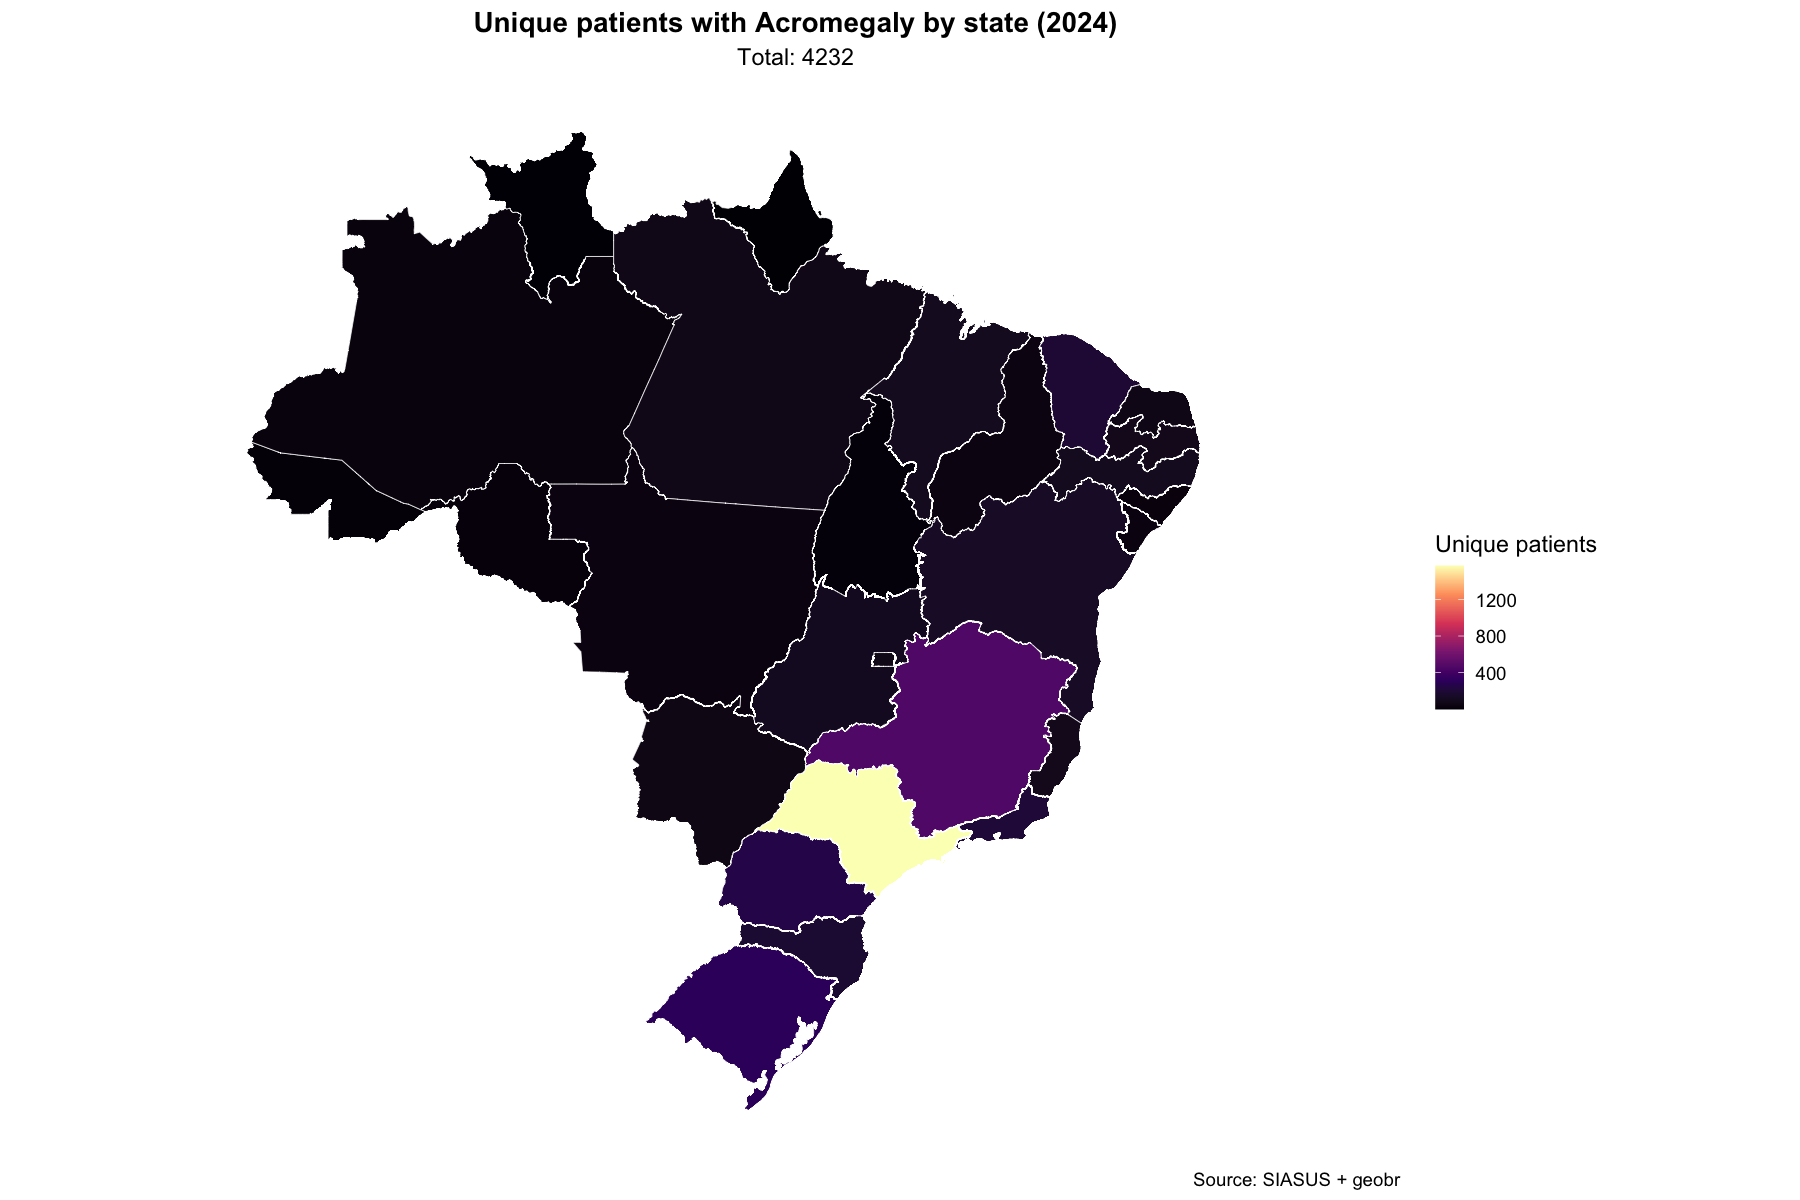

In [ ]:
# Mapa por UF - Pacientes únicos com acromegalia (2024)
library(geobr)      # Para shape do Brasil por unidade federativa
library(sf)
library(ggplot2)

# Carregar shape das UFs do Brasil (geobr só aceita certos anos)
ufs_shape <- geobr::read_state(year = 2020)

# Garantir nomes para merge
pacientes_por_uf_plot <- pacientes_por_uf %>%
  filter(uf_sigla != "TOTAL") %>%
  mutate(uf_sigla = as.character(uf_sigla))

# Junta shape+dados
mapa_dados <- ufs_shape %>%
  left_join(pacientes_por_uf_plot, by = c("abbrev_state" = "uf_sigla"))

# Plot
p_mapa_uf <- ggplot(mapa_dados) +
  geom_sf(aes(fill = quantidade_pacientes), color = "white", size = 0.2) +
  scale_fill_viridis_c(option = "A", name = "Unique patients", na.value = "gray90") +
  labs(
    title = "Unique patients with Acromegaly by state (2024)",
    subtitle = paste0("Total: ", sum(pacientes_por_uf_plot$quantidade_pacientes)),
    caption = "Source: SIASUS + geobr",
    x = NULL, y = NULL
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    panel.grid = element_blank(),
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5),
    legend.position = "right"
  )

print(p_mapa_uf)

# Salvar o mapa
ggsave(gerar_nome_png("mapa_uf"), plot = p_mapa_uf, width = 10, height = 8, dpi = 300)
ggsave(sprintf("../resultados/%s_mapa_acromegalia.png", format(Sys.Date(), "%Y%m%d")), plot = p_mapa_uf, width = 10, height = 8, dpi = 300)

Using year/date 2020




=== INFORMAÇÕES DOS QUARTIS ===
Q1 (0-25%): 1 - 30 
Q2 (25-50%): 30 - 70 
Q3 (50-75%): 70 - 156.5 
Q4 (75-100%): 156.5 - 1567 


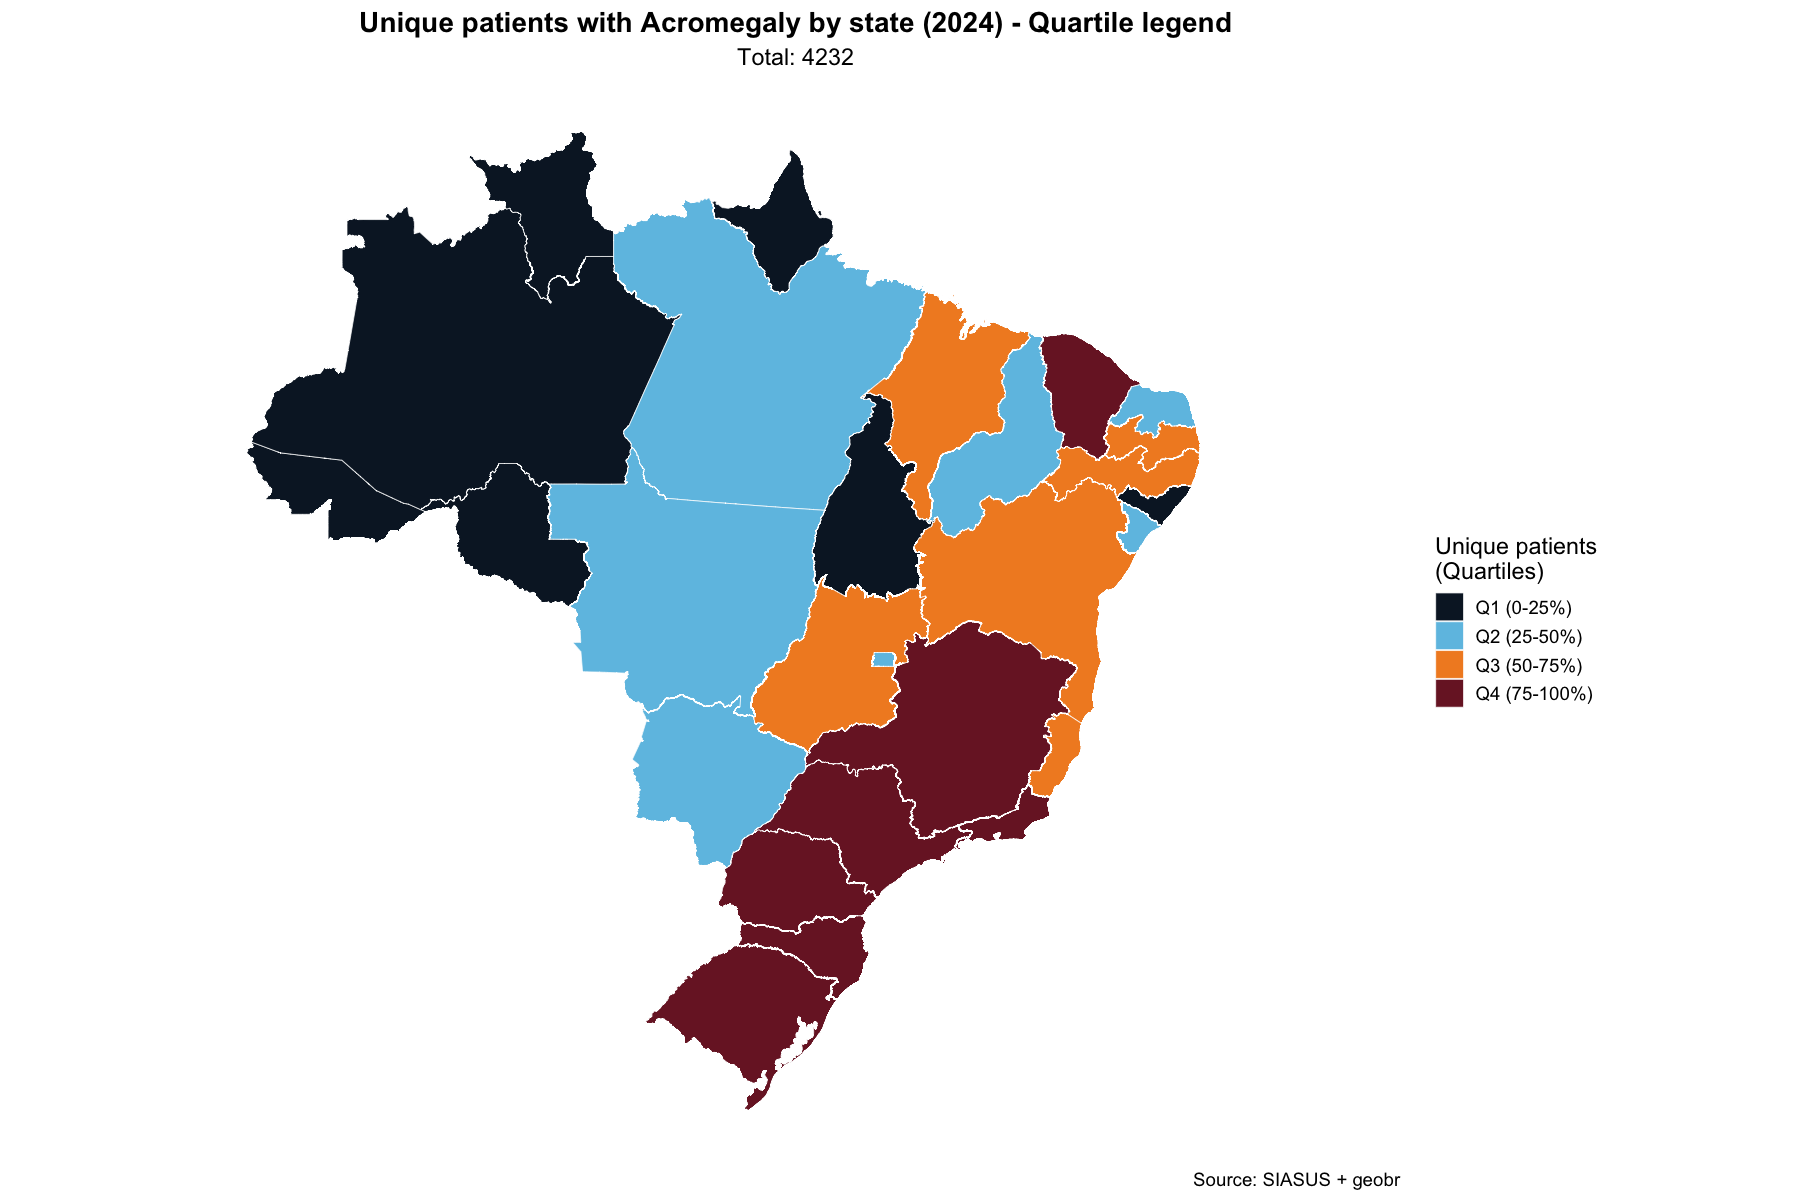

In [ ]:
# Mapa por UF - Pacientes únicos com acromegalia (2024) - Legenda em Quartis
library(geobr)      # Para shape do Brasil por unidade federativa
library(sf)
library(ggplot2)

# Carregar shape das UFs do Brasil (geobr só aceita certos anos)
ufs_shape <- geobr::read_state(year = 2020)

# Garantir nomes para merge
pacientes_por_uf_plot <- pacientes_por_uf %>%
  filter(uf_sigla != "TOTAL") %>%
  mutate(uf_sigla = as.character(uf_sigla))

# Calcular quartis
quartis <- quantile(pacientes_por_uf_plot$quantidade_pacientes, probs = c(0, 0.25, 0.50, 0.75, 1), na.rm = TRUE)

# Criar variável categórica baseada em quartis
pacientes_por_uf_plot <- pacientes_por_uf_plot %>%
  mutate(
    quartil = case_when(
      quantidade_pacientes <= quartis[2] ~ "Q1 (0-25%)",
      quantidade_pacientes <= quartis[3] ~ "Q2 (25-50%)",
      quantidade_pacientes <= quartis[4] ~ "Q3 (50-75%)",
      quantidade_pacientes <= quartis[5] ~ "Q4 (75-100%)",
      TRUE ~ NA_character_
    ),
    quartil = factor(quartil, levels = c("Q1 (0-25%)", "Q2 (25-50%)", "Q3 (50-75%)", "Q4 (75-100%)"))
  )

# Junta shape+dados
mapa_dados <- ufs_shape %>%
  left_join(pacientes_por_uf_plot, by = c("abbrev_state" = "uf_sigla"))

# Plot com quartis
p_mapa_uf_quartis <- ggplot(mapa_dados) +
  geom_sf(aes(fill = quartil), color = "white", size = 0.2) +
  scale_fill_manual(
    values = c("Q1 (0-25%)" = "#0B1C2D",    
               "Q2 (25-50%)" = "#6EC1E4",   
               "Q3 (50-75%)" = "#F28C28",   
               "Q4 (75-100%)" = "#7A1E2D"), 
    name = "Unique patients\n(Quartiles)",
    na.value = "gray90"
  ) +
  labs(
    title = "Unique patients with Acromegaly by state (2024) - Quartile legend",
    subtitle = paste0("Total: ", sum(pacientes_por_uf_plot$quantidade_pacientes, na.rm = TRUE)),
    caption = "Source: SIASUS + geobr",
    x = NULL, y = NULL
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    panel.grid = element_blank(),
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5),
    legend.position = "right"
  )

print(p_mapa_uf_quartis)

# Salvar o mapa
ggsave(gerar_nome_png("mapa_uf_quartis"), plot = p_mapa_uf_quartis, width = 10, height = 8, dpi = 300)
ggsave(sprintf("../resultados/%s_mapa_acromegalia_quartis.png", format(Sys.Date(), "%Y%m%d")), plot = p_mapa_uf_quartis, width = 10, height = 8, dpi = 300)

# Mostrar informações dos quartis
cat("\n=== INFORMAÇÕES DOS QUARTIS ===\n")
cat("Q1 (0-25%):", quartis[1], "-", quartis[2], "\n")
cat("Q2 (25-50%):", quartis[2], "-", quartis[3], "\n")
cat("Q3 (50-75%):", quartis[3], "-", quartis[4], "\n")
cat("Q4 (75-100%):", quartis[4], "-", quartis[5], "\n")

Using year/date 2020




=== INFORMAÇÕES DOS QUARTIS DE PREVALÊNCIA (por 100 mil hab.) ===
Q1 (0-25%): 0.11 - 0.86 
Q2 (25-50%): 0.86 - 1.37 
Q3 (50-75%): 1.37 - 2.15 
Q4 (75-100%): 2.15 - 3.36 

=== TAXAS DE PREVALÊNCIA POR UF ===
# A tibble: 27 × 5
   uf_sigla quantidade_pacientes populacao taxa_prevalencia quartil_prevalencia
   <chr>                   <int>     <dbl>            <dbl> <fct>              
 1 SP                       1567  46649132             3.36 Q4 (75-100%)       
 2 RS                        302  11466630             2.63 Q4 (75-100%)       
 3 SC                        178   7338473             2.43 Q4 (75-100%)       
 4 DF                         70   3094325             2.26 Q4 (75-100%)       
 5 MS                         62   2839188             2.18 Q4 (75-100%)       
 6 PR                        252  11597484             2.17 Q4 (75-100%)       
 7 MG                        462  21411923             2.16 Q4 (75-100%)       
 8 PB                         87   4059905           

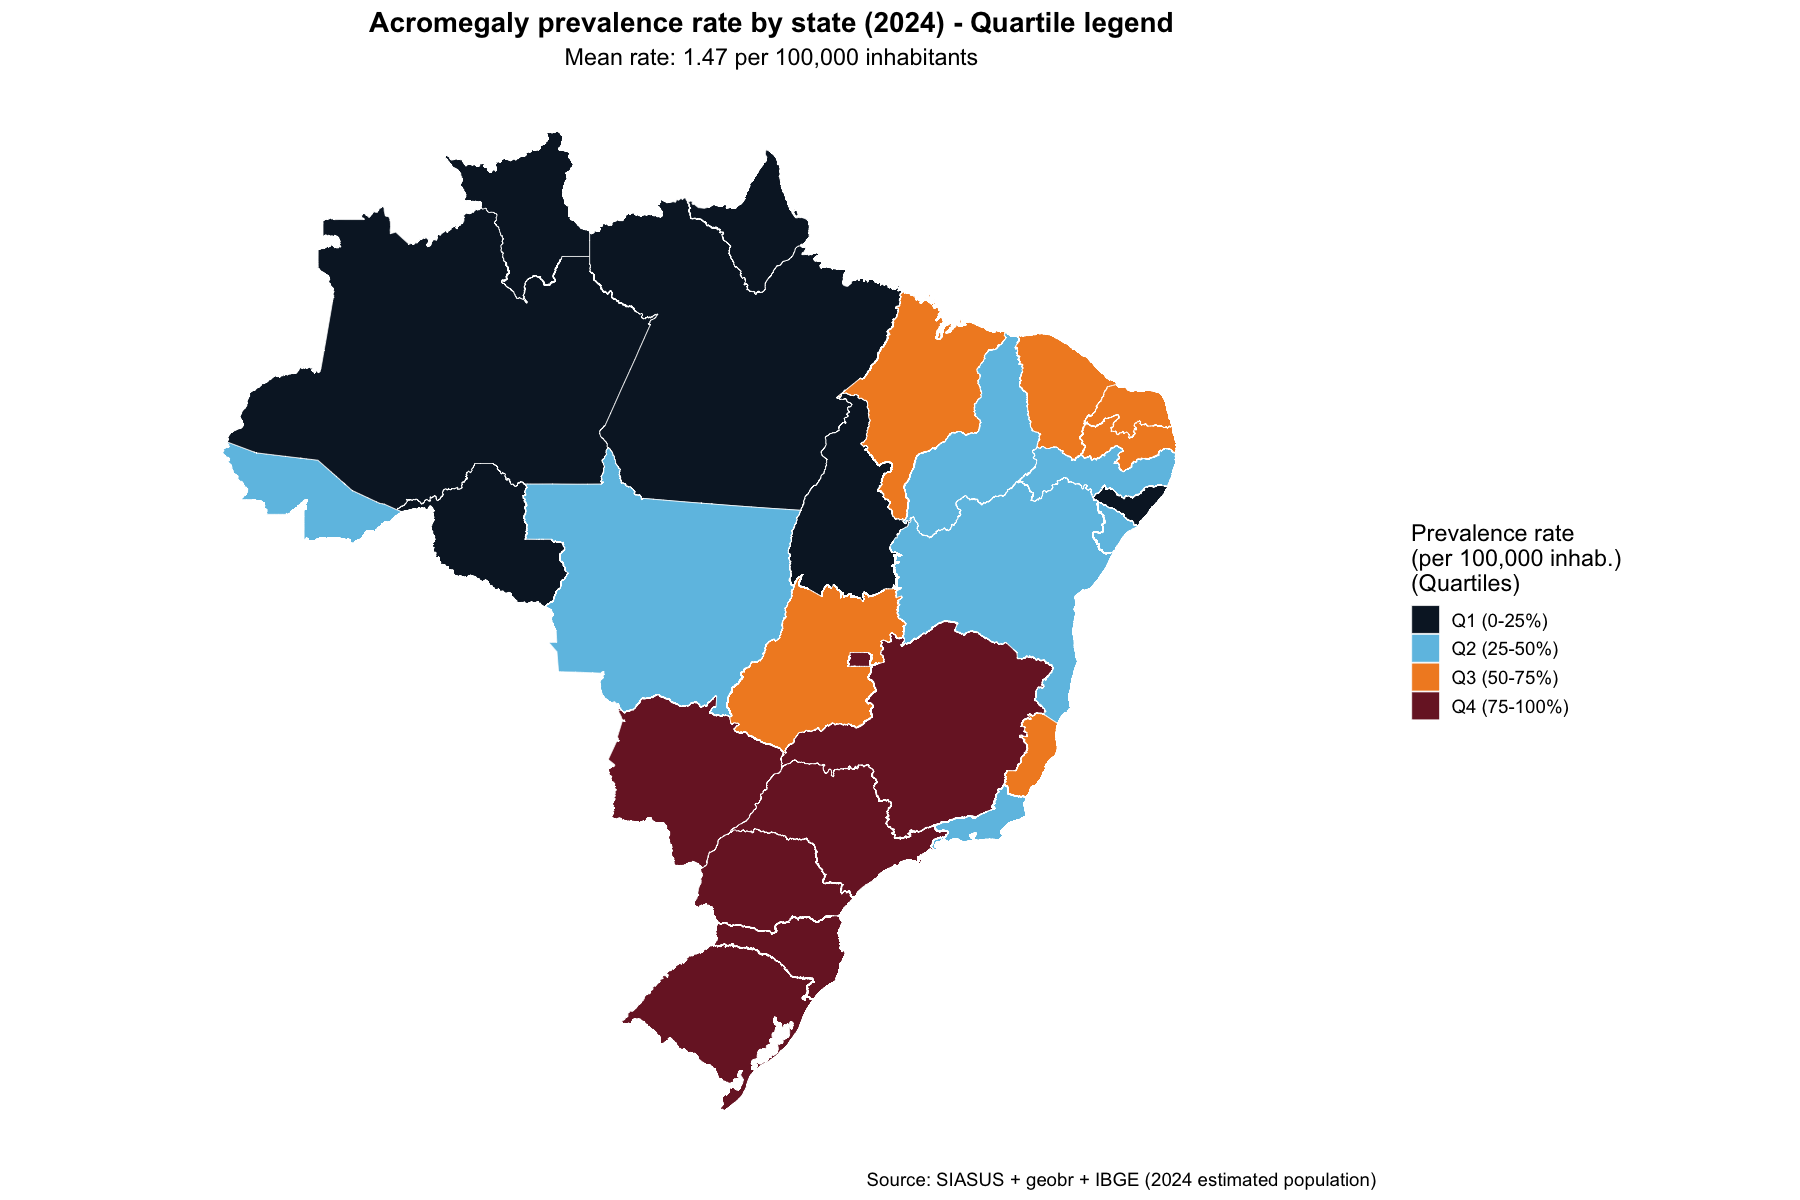

In [ ]:
# Mapa por UF - Taxa de Prevalência de Acromegalia (2024) - Legenda em Quartis
library(geobr)      # Para shape do Brasil por unidade federativa
library(sf)
library(ggplot2)

# Populações por UF (2024)
populacao_uf <- data.frame(
  codigo_uf = c("11", "12", "13", "14", "15", "16", "17", 
                "21", "22", "23", "24", "25", "26", "27", "28", "29",
                "31", "32", "33", "35",
                "41", "42", "43",
                "50", "51", "52", "53"),
  uf_sigla = c("RO", "AC", "AM", "RR", "PA", "AP", "TO",
               "MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA",
               "MG", "ES", "RJ", "SP",
               "PR", "SC", "RS",
               "MS", "MT", "GO", "DF"),
  populacao = c(1815278, 906876, 4269995, 652713, 8777124, 877613, 1607363,
                7153262, 3289290, 9240580, 3560903, 4059905, 9674793, 3365351, 2338474, 14985284,
                21411923, 4108508, 17463349, 46649132,
                11597484, 7338473, 11466630,
                2839188, 3567234, 7206589, 3094325)
)

# Carregar shape das UFs do Brasil
ufs_shape <- geobr::read_state(year = 2020)

# Preparar dados de pacientes por UF
pacientes_por_uf_plot <- pacientes_por_uf %>%
  filter(uf_sigla != "TOTAL") %>%
  mutate(uf_sigla = as.character(uf_sigla)) %>%
  left_join(populacao_uf, by = "uf_sigla") %>%
  mutate(
    taxa_prevalencia = (quantidade_pacientes / populacao) * 100000  # Taxa por 100 mil habitantes
  )

# Calcular quartis das taxas de prevalência
quartis_prevalencia <- quantile(pacientes_por_uf_plot$taxa_prevalencia, probs = c(0, 0.25, 0.50, 0.75, 1), na.rm = TRUE)

# Criar variável categórica baseada em quartis
pacientes_por_uf_plot <- pacientes_por_uf_plot %>%
  mutate(
    quartil_prevalencia = case_when(
      taxa_prevalencia <= quartis_prevalencia[2] ~ "Q1 (0-25%)",
      taxa_prevalencia <= quartis_prevalencia[3] ~ "Q2 (25-50%)",
      taxa_prevalencia <= quartis_prevalencia[4] ~ "Q3 (50-75%)",
      taxa_prevalencia <= quartis_prevalencia[5] ~ "Q4 (75-100%)",
      TRUE ~ NA_character_
    ),
    quartil_prevalencia = factor(quartil_prevalencia, levels = c("Q1 (0-25%)", "Q2 (25-50%)", "Q3 (50-75%)", "Q4 (75-100%)"))
  )

# Junta shape+dados
mapa_dados_prevalencia <- ufs_shape %>%
  left_join(pacientes_por_uf_plot, by = c("abbrev_state" = "uf_sigla"))

# Plot com quartis de prevalência
p_mapa_uf_prevalencia <- ggplot(mapa_dados_prevalencia) +
  geom_sf(aes(fill = quartil_prevalencia), color = "white", size = 0.2) +
  scale_fill_manual(
    values = c("Q1 (0-25%)" = "#0B1C2D",    
               "Q2 (25-50%)" = "#6EC1E4",   
               "Q3 (50-75%)" = "#F28C28",   
               "Q4 (75-100%)" = "#7A1E2D"), 
    name = "Prevalence rate
(per 100,000 inhab.)
(Quartiles)",
    na.value = "gray90"
  ) +
  labs(
    title = "Acromegaly prevalence rate by state (2024) - Quartile legend",
    subtitle = paste0("Mean rate: ", round(mean(pacientes_por_uf_plot$taxa_prevalencia, na.rm = TRUE), 2), " per 100,000 inhabitants"),
    caption = "Source: SIASUS + geobr + IBGE (2024 estimated population)",
    x = NULL, y = NULL
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    panel.grid = element_blank(),
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5),
    legend.position = "right"
  )

print(p_mapa_uf_prevalencia)

# Salvar o mapa
ggsave(gerar_nome_png("mapa_uf_prevalencia"), plot = p_mapa_uf_prevalencia, width = 10, height = 8, dpi = 300)
ggsave(sprintf("../resultados/%s_mapa_acromegalia_prevalencia.png", format(Sys.Date(), "%Y%m%d")), plot = p_mapa_uf_prevalencia, width = 10, height = 8, dpi = 300)

# Mostrar informações dos quartis de prevalência
cat("\n=== INFORMAÇÕES DOS QUARTIS DE PREVALÊNCIA (por 100 mil hab.) ===\n")
cat("Q1 (0-25%):", round(quartis_prevalencia[1], 2), "-", round(quartis_prevalencia[2], 2), "\n")
cat("Q2 (25-50%):", round(quartis_prevalencia[2], 2), "-", round(quartis_prevalencia[3], 2), "\n")
cat("Q3 (50-75%):", round(quartis_prevalencia[3], 2), "-", round(quartis_prevalencia[4], 2), "\n")
cat("Q4 (75-100%):", round(quartis_prevalencia[4], 2), "-", round(quartis_prevalencia[5], 2), "\n")

# Mostrar tabela com taxas por UF
cat("\n=== TAXAS DE PREVALÊNCIA POR UF ===\n")
tabela_prevalencia <- pacientes_por_uf_plot %>%
  select(uf_sigla, quantidade_pacientes, populacao, taxa_prevalencia, quartil_prevalencia) %>%
  arrange(desc(taxa_prevalencia)) %>%
  mutate(
    taxa_prevalencia = round(taxa_prevalencia, 2)
  )
print(tabela_prevalencia)